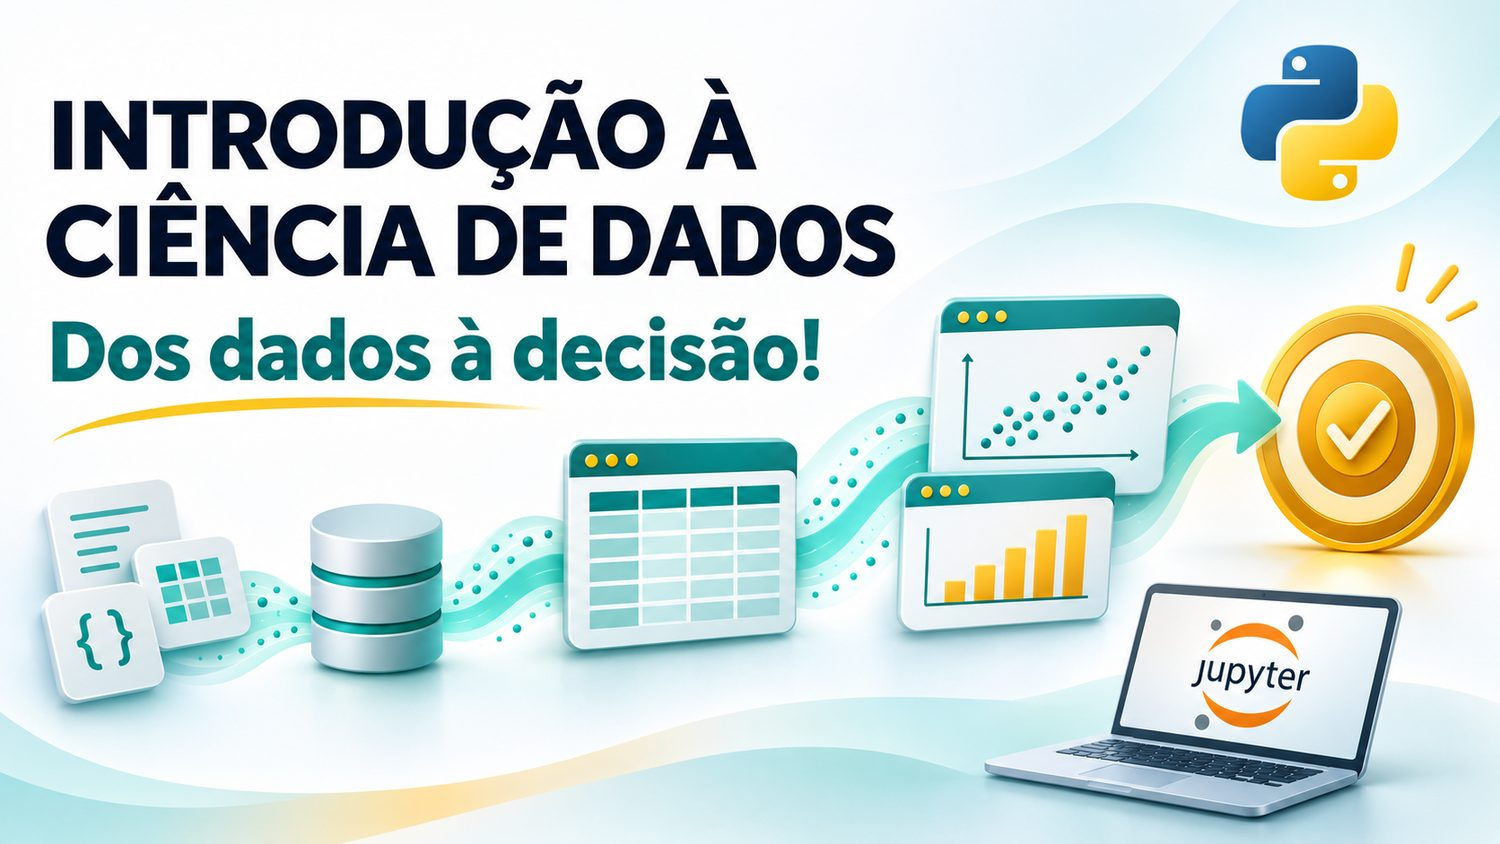

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/05_Codificar_Categorias.ipynb)

# Capítulo 5 – Codificar categorias

Os modelos fazem contas, e as contas fazem-se com números. A marca, o segmento e o estado de um carro são palavras. Este capítulo mostra como transformar categorias em números sem lhes dar um significado que não têm, e o que fazer com as categorias raras e com as que o modelo nunca viu.

> **Objetivos:** explicar porque não se numeram categorias nominais; aplicar a codificação *one-hot*; codificar variáveis ordinais respeitando a ordem; tratar categorias raras, desconhecidas e com muitos valores; criar atributos a partir de datas; aprender a codificação só no treino.

**Pré-requisitos:** capítulos 1 a 4 deste módulo, e o capítulo 2 do módulo 2 (tipos de dados).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_carros(n=3000, semente=17):
    """Gera anúncios de carros usados de um stand fictício (dados sintéticos; as marcas são inventadas)."""
    rng = np.random.default_rng(semente)
    segmentos = {"citadino": (11000, 75), "utilitário": (15000, 100), "familiar": (21000, 130),
                 "SUV": (27000, 150), "monovolume": (23000, 125), "desportivo": (38000, 240)}
    marcas = {"Alba": 1.00, "Boreal": 0.92, "Cimo": 1.08, "Dueto": 0.95, "Estela": 1.30, "Faro": 1.00,
              "Gávea": 0.88, "Hera": 1.45, "Ípsilon": 1.05, "Jade": 0.97, "Kappa": 1.60, "Lume": 0.90}
    frequencia = np.array([18, 16, 14, 12, 9, 9, 7, 5, 4, 3, 2, 1], dtype=float)
    segmento = rng.choice(list(segmentos), n, p=[0.24, 0.28, 0.18, 0.18, 0.08, 0.04])
    marca = rng.choice(list(marcas), n, p=frequencia / frequencia.sum())
    ano = rng.integers(2008, 2026, n)
    idade = 2026 - ano
    km = (idade * 14000 * rng.lognormal(0, 0.35, n) + rng.uniform(500, 6000, n)).round(-2)
    potencia = np.array([segmentos[s][1] for s in segmento]) * rng.normal(1, 0.12, n)
    prob_eletrico = np.clip((ano - 2016) * 0.03, 0, 0.25)
    sorteio = rng.random(n)
    combustivel = np.where(sorteio < prob_eletrico, "elétrico", np.where(sorteio < prob_eletrico + 0.15, "híbrido",
                           np.where(sorteio < prob_eletrico + 0.55, "gasóleo", "gasolina")))
    caixa_velocidades = np.where(rng.random(n) < 0.25 + 0.4 * (combustivel == "elétrico"), "automática", "manual")
    niveis = np.array(["mau", "razoável", "bom", "excelente"])
    estado = niveis[np.clip(rng.normal(2.2 - 0.06 * idade, 0.8, n).round(), 0, 3).astype(int)]
    fator_estado = pd.Series(estado).map({"mau": 0.78, "razoável": 0.92, "bom": 1.0, "excelente": 1.08}).to_numpy()
    ruido = rng.lognormal(0, 0.10, n)                      # o que o preço tem de «caro» ou de «barato» sem explicação
    preco = (np.array([segmentos[s][0] for s in segmento]) * np.array([marcas[m] for m in marca])
             * np.exp(-0.085 * idade) * np.exp(-km / 420000) * fator_estado
             * np.where(caixa_velocidades == "automática", 1.08, 1.0)
             * np.where(combustivel == "elétrico", 1.25, np.where(combustivel == "híbrido", 1.12, 1.0))
             * (potencia / np.array([segmentos[s][1] for s in segmento])) ** 0.4 * ruido)
    carros = pd.DataFrame({
        "marca": marca, "segmento": segmento, "ano": ano, "km": km, "potencia_cv": potencia.round(),
        "combustivel": combustivel, "caixa": caixa_velocidades, "estado": estado,
        "cor": rng.choice(["branco", "cinzento", "preto", "azul", "vermelho"], n), "preco": preco.round(-1)})
    nivel = pd.Series(estado).map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}).to_numpy()
    z = (-0.2 + 0.75 * (nivel - 1.5) - 0.07 * idade + 0.7 * np.isin(segmento, ["SUV", "utilitário"])
         + 0.5 * (caixa_velocidades == "automática") - 5 * np.log(ruido))
    carros["vendido_30_dias"] = rng.random(n) < 1 / (1 + np.exp(-z))
    # Valores em falta: quem tem muitos quilómetros «esquece-se» mais vezes de os indicar
    carros.loc[rng.random(n) < 0.03 + 0.25 * (km > np.quantile(km, 0.8)), "km"] = np.nan
    carros.loc[rng.random(n) < 0.06, "potencia_cv"] = np.nan
    carros.loc[rng.random(n) < 0.05, "estado"] = np.nan
    return carros


carros = gerar_carros()
carros.head()

,marca,segmento,ano,km,potencia_cv,combustivel,caixa,estado,cor,preco,vendido_30_dias
0,Boreal,SUV,2019,127500.0,199.0,híbrido,automática,razoável,cinzento,15250.0,False
1,Gávea,citadino,2012,171200.0,67.0,gasolina,manual,bom,azul,1630.0,False
2,Gávea,familiar,2018,123900.0,116.0,gasóleo,automática,bom,preto,6670.0,True
3,Cimo,utilitário,2009,239000.0,98.0,gasolina,manual,bom,cinzento,2350.0,False
4,Boreal,citadino,2016,122600.0,51.0,gasóleo,manual,bom,branco,3080.0,False


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

dados = carros.dropna().assign(idade=lambda t: 2026 - t["ano"]).reset_index(drop=True)     # só linhas completas, para isolar o tema
treino, teste = train_test_split(dados, test_size=0.25, random_state=0)
numericos = ["idade", "km", "potencia_cv"]
print(dados.select_dtypes(exclude="number").drop(columns="vendido_30_dias").nunique())

marca          12
segmento        6
combustivel     4
caixa           2
estado          4
cor             5
dtype: int64


Há seis colunas de texto, com 2 a 12 valores diferentes cada uma. Até aqui, os nossos modelos ignoraram-nas. Entre elas estão o **segmento** e a **marca**, que qualquer pessoa usaria em primeiro lugar para avaliar um carro.

## O erro mais comum: numerar as categorias

A forma mais rápida de transformar palavras em números é atribuir um número a cada uma.

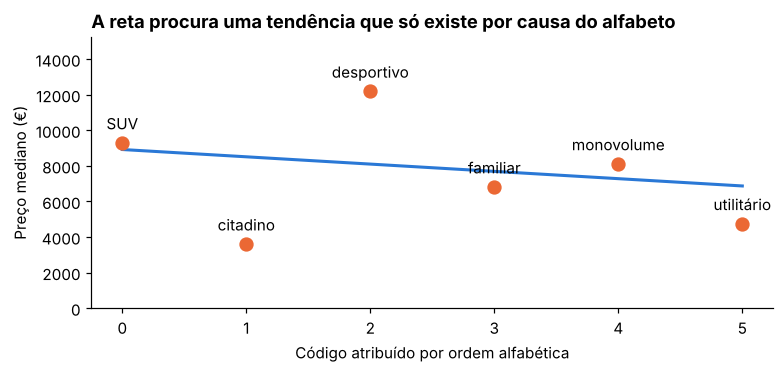

{'SUV': 0, 'citadino': 1, 'desportivo': 2, 'familiar': 3, 'monovolume': 4, 'utilitário': 5}


In [4]:
codigos = {segmento: i for i, segmento in enumerate(sorted(dados["segmento"].unique()))}
preco_mediano = treino.groupby("segmento")["preco"].median()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter([codigos[s] for s in preco_mediano.index], preco_mediano, s=70, color=LARANJA, zorder=3)
for segmento, preco in preco_mediano.items():
    ax.annotate(segmento, (codigos[segmento], preco), textcoords="offset points", xytext=(0, 9), ha="center")
declive, ordenada = np.polyfit([codigos[s] for s in treino["segmento"]], treino["preco"], 1)
ax.plot([0, 5], [ordenada, ordenada + 5 * declive], color=AZUL, lw=2)
ax.set_xticks(range(6))
ax.set_xlabel("Código atribuído por ordem alfabética")
ax.set_ylabel("Preço mediano (€)")
ax.set_ylim(0, preco_mediano.max() * 1.25)
ax.set_title("A reta procura uma tendência que só existe por causa do alfabeto")
plt.show()

print(codigos)

Ao numerar, afirmámos três coisas falsas:

- que há uma **ordem**: `SUV` (0) vem antes de `citadino` (1), que vem antes de `desportivo` (2)…;
- que as **distâncias** são iguais: de `SUV` para `citadino` vai o mesmo que de `familiar` para `monovolume`;
- que faz sentido fazer **contas**: a «média» de um SUV e de um desportivo seria um citadino.

Um modelo linear, que só sabe multiplicar o código por um coeficiente, é obrigado a traçar uma reta por pontos que não estão em linha nenhuma. Um modelo de vizinhos passa a achar que um SUV é «mais parecido» com um citadino do que com um utilitário. Se as categorias tivessem saído por outra ordem, os modelos seriam outros.

O módulo 2 já tinha avisado: numa variável **nominal** só se pode contar. Numerá-la é tratá-la como uma quantidade.

## A codificação *one-hot*

A solução é criar **uma coluna por categoria**, com 1 na categoria do carro e 0 nas outras. Chama-se codificação *one-hot* (em cada linha, só uma coluna está «acesa»), ou variáveis indicadoras.

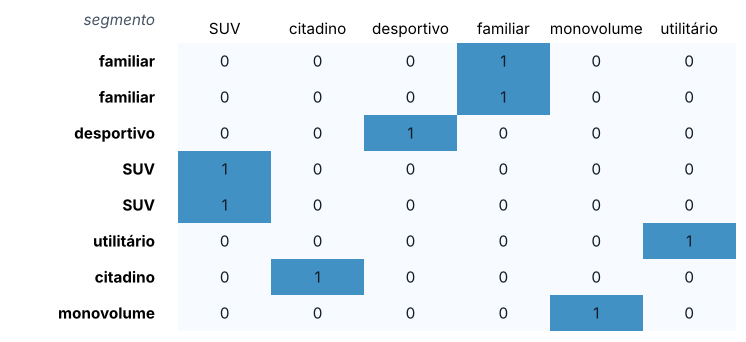

In [5]:
exemplo = treino[["segmento"]].head(8)
indicadoras = pd.get_dummies(exemplo["segmento"]).astype(int).reindex(columns=sorted(codigos), fill_value=0)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.imshow(indicadoras, cmap="Blues", vmin=0, vmax=1.6, aspect="auto")
for i in range(indicadoras.shape[0]):
    ax.text(-0.75, i, exemplo["segmento"].iloc[i], ha="right", va="center", fontweight="bold")
    for j in range(indicadoras.shape[1]):
        ax.text(j, i, indicadoras.iloc[i, j], ha="center", va="center", color=TINTA)
ax.set_xticks(range(6), indicadoras.columns)
ax.xaxis.tick_top()
ax.set_yticks([])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_xlim(-2.3, 5.5)
ax.text(-0.75, -1.0, "segmento", ha="right", style="italic", color="#465463")
plt.show()

Cada categoria tem a sua coluna, e nenhuma é «maior» do que outra. O modelo linear ganha um coeficiente por segmento, ou seja, um preço de partida para cada um, sem ser obrigado a alinhá-los. E para um modelo de distâncias, dois carros de segmentos diferentes ficam todos à mesma distância uns dos outros.

Com o pandas, faz-se com `get_dummies`. Com o scikit-learn, com `OneHotEncoder`, que tem a vantagem de separar o `fit` do `transform`, como o imputador e a escala.

In [6]:
from sklearn.preprocessing import OneHotEncoder

codificador = OneHotEncoder(sparse_output=False).fit(treino[["segmento"]])       # aprende as categorias no treino
print("Categorias aprendidas:", codificador.categories_[0].tolist())
print(codificador.transform(teste[["segmento"]].head(3)))

Categorias aprendidas: ['SUV', 'citadino', 'desportivo', 'familiar', 'monovolume', 'utilitário']
[[1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]]


### O efeito no modelo

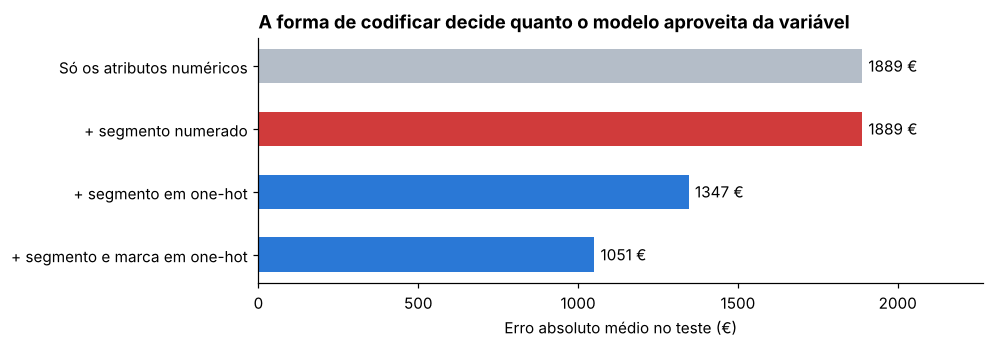

In [7]:
def erro(X_treino, X_teste):
    modelo = LinearRegression().fit(X_treino, np.log10(treino["preco"]))          # prevemos o logaritmo do preço (capítulo 4)
    return mean_absolute_error(teste["preco"], 10 ** modelo.predict(X_teste))


def com_codigo(tabela):
    return tabela[numericos].assign(segmento=tabela["segmento"].map(codigos))


def com_one_hot(tabela, colunas):
    c = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(treino[colunas])
    return np.hstack([tabela[numericos].to_numpy(), c.transform(tabela[colunas])])


resultados = {"Só os atributos numéricos": erro(treino[numericos], teste[numericos]),
              "+ segmento numerado": erro(com_codigo(treino), com_codigo(teste)),
              "+ segmento em one-hot": erro(com_one_hot(treino, ["segmento"]), com_one_hot(teste, ["segmento"])),
              "+ segmento e marca em one-hot": erro(com_one_hot(treino, ["segmento", "marca"]), com_one_hot(teste, ["segmento", "marca"]))}

fig, ax = plt.subplots(figsize=(8.5, 2.9))
barras = ax.barh(list(resultados), list(resultados.values()), color=[CINZA, MAU, AZUL, AZUL], height=0.55)
ax.bar_label(barras, fmt="%.0f €", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(resultados.values()) * 1.2)
ax.set_xlabel("Erro absoluto médio no teste (€)")
ax.set_title("A forma de codificar decide quanto o modelo aproveita da variável")
plt.show()

O segmento numerado não ajuda nada: a informação está lá, mas numa forma que a reta não consegue usar. Em *one-hot*, a mesma coluna reduz o erro de forma clara, e a marca reduz ainda mais.

Nenhuma técnica dos capítulos anteriores teve um efeito comparável. Dar ao modelo os atributos certos, numa forma que ele consiga usar, vale mais do que afinar a imputação ou a escala.

## Variáveis ordinais: quando há ordem, usa-se

O estado do carro tem uma ordem: mau < razoável < bom < excelente. Aqui, numerar faz sentido, **desde que os números sigam a ordem verdadeira**.

In [8]:
from sklearn.preprocessing import OrdinalEncoder

ordem = ["mau", "razoável", "bom", "excelente"]
alfabetica = OrdinalEncoder().fit(treino[["estado"]])
correta = OrdinalEncoder(categories=[ordem]).fit(treino[["estado"]])
comparacao = pd.DataFrame({"estado": ordem,
                           "por omissão (alfabética)": alfabetica.transform(pd.DataFrame({"estado": ordem})).ravel().astype(int),
                           "com a ordem indicada": correta.transform(pd.DataFrame({"estado": ordem})).ravel().astype(int)})
print(comparacao.to_string(index=False))

   estado  por omissão (alfabética)  com a ordem indicada
      mau                         2                     0
 razoável                         3                     1
      bom                         0                     2
excelente                         1                     3


Por omissão, o `OrdinalEncoder` numera por ordem alfabética, e põe `excelente` (1) entre `bom` (0) e `mau` (2). É o erro da secção anterior, agora numa variável em que a ordem certa existia. Indica sempre a ordem com `categories`.

Numerar uma variável ordinal é uma aproximação: pressupõe que de «mau» para «razoável» vai o mesmo que de «bom» para «excelente». Quando há dúvidas, a codificação *one-hot* também serve para ordinais: gasta mais colunas e não pressupõe nada.

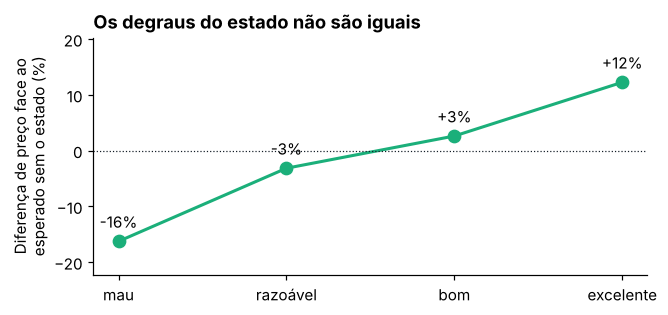

In [9]:
preco_relativo = treino.assign(log_preco=np.log10(treino["preco"]))
residuo = preco_relativo["log_preco"] - LinearRegression().fit(com_one_hot(treino, ["segmento", "marca"]), preco_relativo["log_preco"]).predict(com_one_hot(treino, ["segmento", "marca"]))
efeito = (10 ** residuo.groupby(treino["estado"]).mean().loc[ordem] - 1) * 100

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(ordem, efeito, color=VERDE, lw=2, marker="o", ms=8)
for nivel, valor in efeito.items():
    ax.annotate(f"{valor:+.0f}%", (nivel, valor), textcoords="offset points", xytext=(0, 9), ha="center")
ax.axhline(0, color=TINTA, lw=0.8, ls=":")
ax.set_ylabel("Diferença de preço face ao\nesperado sem o estado (%)")
ax.set_ylim(efeito.min() - 6, efeito.max() + 8)
ax.set_title("Os degraus do estado não são iguais")
plt.show()

O gráfico mostra quanto o preço se afasta do que seria de esperar pelos outros atributos, em cada estado. Sobe sempre, o que confirma a ordem, mas os degraus não são iguais: o de «mau» para «razoável» é o maior. Com a codificação ordinal, o modelo linear trata-os como iguais; com *one-hot*, aprende cada um.

## Três complicações

### Categorias raras

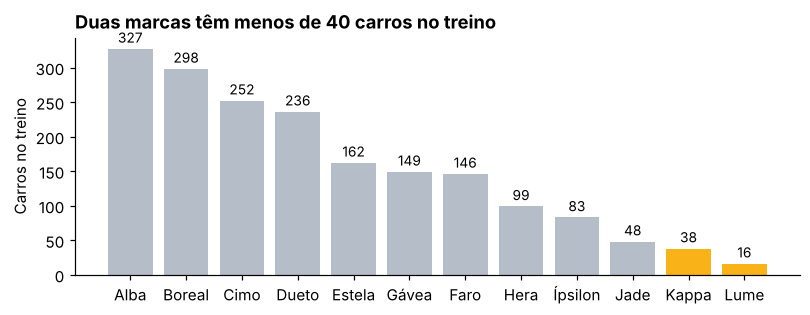

In [10]:
contagem = treino["marca"].value_counts()
fig, ax = plt.subplots(figsize=(8.5, 2.8))
barras = ax.bar(contagem.index, contagem, color=[CINZA if n >= 40 else AVISO for n in contagem])
ax.bar_label(barras, padding=2, fontsize=9)
ax.set_ylabel("Carros no treino")
ax.set_title("Duas marcas têm menos de 40 carros no treino")
plt.show()

Uma marca com dezasseis carros no treino tem a sua coluna *one-hot* quase sempre a zero. O coeficiente que o modelo lhe atribui baseia-se em dezasseis exemplos: é pouco fiável, e pode refletir dois ou três carros invulgares.

A solução habitual é juntar as categorias raras numa só, «outra». O `OneHotEncoder` faz isso com `min_frequency`.

In [11]:
agrupador = OneHotEncoder(sparse_output=False, min_frequency=40, handle_unknown="infrequent_if_exist").fit(treino[["marca"]])
print("Colunas produzidas:", [c.replace("marca_", "") for c in agrupador.get_feature_names_out()])

Colunas produzidas: ['Alba', 'Boreal', 'Cimo', 'Dueto', 'Estela', 'Faro', 'Gávea', 'Hera', 'Jade', 'Ípsilon', 'infrequent_sklearn']


As duas marcas com menos de 40 carros ficaram numa única coluna, `infrequent_sklearn`. Perde-se a distinção entre elas e ganha-se um coeficiente apoiado em mais exemplos.

### Categorias que o modelo nunca viu

Depois de treinado, o modelo vai receber carros novos. Mais cedo ou mais tarde, chega um de uma marca que não existia no treino.

In [12]:
carro_novo = pd.DataFrame({"marca": ["Zénite"]})
try:
    OneHotEncoder(sparse_output=False).fit(treino[["marca"]]).transform(carro_novo)
except ValueError as excecao:
    print("⚠️ Erro de propósito:", str(excecao)[:75])

tolerante = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(treino[["marca"]])
print("\nCom handle_unknown='ignore':", tolerante.transform(carro_novo).astype(int).tolist()[0])

⚠️ Erro de propósito: Found unknown categories ['Zénite'] in column 0 during transform

Com handle_unknown='ignore': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Por omissão, o codificador dá erro, e o sistema do stand pararia nesse carro. Com `handle_unknown="ignore"`, a marca desconhecida fica com zeros em todas as colunas: o modelo trata-a como «nenhuma das que conheço» e faz a previsão com os outros atributos.

Esta situação só aparece quando o modelo já está a ser usado, e por isso convém decidir de antemão o que fazer. É também mais uma razão para aprender as categorias **só no treino**: se uma marca existir apenas no teste, é exatamente este caso, e o teste deve mostrá-lo.

### Muitas categorias

A codificação *one-hot* cria uma coluna por categoria. Com 12 marcas, são 12 colunas. Com o **modelo** do carro, seriam centenas; com o código postal, milhares. Muitas colunas quase vazias tornam os modelos lentos e instáveis.

| Opção | Ideia | Cuidado |
| --- | --- | --- |
| Agrupar as raras | Manter as mais frequentes e juntar o resto em «outra» | Perde-se detalhe |
| Usar uma hierarquia | Código postal → concelho → distrito | É preciso conhecer o domínio |
| Substituir por um número com significado | A marca pelo seu preço médio de catálogo; o concelho pela sua população | O número tem de vir de fora, e não do alvo |
| Codificar pelo alvo | A marca pelo preço médio dos seus carros **no treino** | Risco sério de fuga de informação: tem de ser feito com muito cuidado |

A última opção é tentadora e perigosa: o atributo passa a conter o alvo. Feita sem cuidado, dá modelos excelentes no treino e fracos em dados novos.

## Booleanos e datas

Os **booleanos** são o caso mais simples: `True` e `False` passam a 1 e 0. Uma categoria com dois valores (caixa manual ou automática) codifica-se da mesma maneira, com uma só coluna.

As **datas** não se dão ao modelo tal como estão. Extrai-se delas o que pode interessar.

In [13]:
rng = np.random.default_rng(0)
anuncios = pd.DataFrame({"data_anuncio": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 500, 5), unit="D")})
anuncios["mes"] = anuncios["data_anuncio"].dt.month
anuncios["dia_semana"] = anuncios["data_anuncio"].dt.dayofweek
anuncios["fim_de_semana"] = (anuncios["dia_semana"] >= 5).astype(int)
anuncios["dias_desde_2025"] = (anuncios["data_anuncio"] - pd.Timestamp("2025-01-01")).dt.days
anuncios

,data_anuncio,mes,dia_semana,fim_de_semana,dias_desde_2025
0,2026-03-02,3,0,0,425
1,2025-11-15,11,5,1,318
2,2025-09-13,9,5,1,255
3,2025-05-15,5,3,0,134
4,2025-06-03,6,1,0,153


Já fizemos isto sem dar nome: a coluna `idade` é `2026 - ano`. A criar atributos novos a partir dos existentes chama-se **engenharia de atributos**, e é onde o conhecimento do domínio mais pesa. Alguns exemplos para o stand:

| Atributo novo | Como se calcula | Porque pode ajudar |
| --- | --- | --- |
| Idade | ano atual − ano de matrícula | O preço depende da idade, e não do ano em si |
| Quilómetros por ano | km ÷ idade | Distingue um carro muito usado de um pouco usado, para a mesma idade |
| Potência relativa | potência ÷ mediana do segmento | Um citadino com 110 cv é potente; um desportivo com 110 cv não |

Atenção ao mês e ao dia da semana: são **cíclicos** (a dezembro segue-se janeiro) e, como números de 1 a 12, sofrem do problema da secção inicial. Em geral codificam-se em *one-hot*.

## Resumo: que codificação usar

| Tipo de variável | Codificação | No scikit-learn |
| --- | --- | --- |
| Nominal, com poucas categorias | *One-hot* | `OneHotEncoder(handle_unknown="ignore")` |
| Nominal, com categorias raras | *One-hot*, com as raras agrupadas | `OneHotEncoder(min_frequency=…)` |
| Ordinal | Números pela ordem verdadeira, ou *one-hot* | `OrdinalEncoder(categories=[…])` |
| Booleana ou com duas categorias | 0 e 1 | `astype(int)`, ou `OneHotEncoder(drop="if_binary")` |
| Data | Atributos extraídos (idade, mês, dia da semana) | pandas (`.dt`) |
| Identificador | Não se usa como atributo | — |

A última linha merece uma nota. Um identificador (a matrícula, o número do anúncio) é diferente em cada linha: em *one-hot*, daria uma coluna por carro, e o modelo decoraria o treino.

## Exercícios

### `Exercício 1` – Que codificação?

Indica a codificação adequada a cada variável:

1. Grupo sanguíneo (A, B, AB, O).
2. Escolaridade (básico, secundário, licenciatura, mestrado, doutoramento).
3. Concelho de residência (308 concelhos).
4. Fumador (sim ou não).
5. Número de contribuinte.
6. Dia da semana.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. *One-hot*: é nominal.
2. Ordinal, com a ordem indicada (ou *one-hot*, se as distâncias entre níveis forem duvidosas).
3. *One-hot* com os concelhos raros agrupados, ou substituir por atributos do concelho (população, distrito).
4. 0 e 1.
5. Nenhuma: é um identificador e não entra no modelo.
6. *One-hot*: é cíclico, e a diferença entre domingo e segunda não é «6».

</details>

### `Exercício 2` – O combustível

Acrescenta o combustível e a caixa, em *one-hot*, ao melhor modelo do capítulo. Quanto desce o erro?

In [14]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for colunas in [["segmento", "marca"], ["segmento", "marca", "combustivel"], ["segmento", "marca", "combustivel", "caixa"]]:
    print(colunas, round(erro(com_one_hot(treino, colunas), com_one_hot(teste, colunas))), "€")
```

O erro volta a descer com cada variável. Os elétricos e os híbridos valem mais do que os outros carros da mesma idade, e a caixa automática também, e o modelo só o podia saber vendo essas colunas.

</details>

### `Exercício 3` – Ordinal ou one-hot para o estado?

Acrescenta o estado ao modelo de duas maneiras: com `OrdinalEncoder` (com a ordem certa) e em *one-hot*. Qual dá o menor erro? A diferença é grande?

In [15]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
base = ["segmento", "marca", "combustivel", "caixa"]
numero = OrdinalEncoder(categories=[ordem]).fit(treino[["estado"]])
ordinal_treino = np.hstack([com_one_hot(treino, base), numero.transform(treino[["estado"]])])
ordinal_teste = np.hstack([com_one_hot(teste, base), numero.transform(teste[["estado"]])])
print("Ordinal:", round(erro(ordinal_treino, ordinal_teste)), "€")
print("One-hot:", round(erro(com_one_hot(treino, base + ["estado"]), com_one_hot(teste, base + ["estado"]))), "€")
```

As duas dão erros muito próximos, com uma pequena vantagem para o *one-hot*, que consegue aprender degraus desiguais. Com só quatro níveis e muitos exemplos de cada um, o custo de gastar quatro colunas em vez de uma é irrelevante.

</details>

### `Exercício 4` – Um atributo novo

Cria o atributo `km_por_ano` e acrescenta-o ao modelo. Ajuda? Explica porque é que um modelo linear pode beneficiar de um atributo que é só uma conta feita com dois que já tinha.

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
numericos_originais = numericos.copy()
for tabela in (treino, teste):
    tabela["km_por_ano"] = tabela["km"] / tabela["idade"]
base = ["segmento", "marca", "combustivel", "caixa", "estado"]
antes = erro(com_one_hot(treino, base), com_one_hot(teste, base))
numericos.append("km_por_ano")
depois = erro(com_one_hot(treino, base), com_one_hot(teste, base))
numericos[:] = numericos_originais
print(f"Sem km_por_ano: {antes:.0f} € | com: {depois:.0f} €")
```

Nestes dados o ganho é pequeno ou nulo: a idade e os quilómetros já dão ao modelo o que ele precisa. Em geral, um modelo linear só sabe somar atributos multiplicados por coeficientes; não consegue, sozinho, dividir um pelo outro. Um atributo que seja uma razão ou um produto dá-lhe uma forma que ele não conseguia construir. As árvores e os vizinhos têm menos esta limitação.

</details>

## Verifica o que aprendeste

- [ ] Sei explicar porque não se numeram categorias nominais.
- [ ] Sei aplicar a codificação *one-hot* com o pandas e com o scikit-learn.
- [ ] Sei codificar uma variável ordinal com a ordem certa.
- [ ] Sei o que fazer com categorias raras e com categorias desconhecidas.
- [ ] Sei as opções para variáveis com muitas categorias, e o risco de codificar pelo alvo.
- [ ] Sei extrair atributos de uma data.
- [ ] Sei porque um identificador não entra no modelo.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features
- https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html
- https://en.wikipedia.org/wiki/One-hot
- https://en.wikipedia.org/wiki/Feature_engineering